**Practical 8: Decision Trees and its Maxdepth**

**Aim**:

To understand and implement a Decision Tree Classifier using the Pima Indians Diabetes Dataset and study how different maximum depth values affect the complexity and performance of the model.

**Objectives**:

1. To understand the working of a Decision Tree Classifier.
2. To prepare the dataset by separating input features and target variables.
3. To divide the dataset into training and testing sets.
4. To build two Decision Tree models using different maximum depth values.
5. To compare the performance and accuracy of both models.
6. To visualize the decision trees and understand their structure.
7. To understand Entropy, Information Gain, and Gini impurity.
8. To identify the root node and understand how the tree makes decisions.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.tree import export_text

In [15]:
df = pd.read_csv("/content/diabetes.csv")
print(df.head())
print(df.shape)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
(768, 9)


**Feature Selection-**

In [16]:
#Independent variables
X = df.drop("Outcome", axis=1)

X =
Pregnancies
Glucose
BloodPressure
SkinThickness
Insulin
BMI
DiabetesPedigreeFunction
Age

Creates X containing all input features except Outcome, which is the target variable.

In [17]:
#Dependent variable
y = df["Outcome"]

Stores the Outcome column as the target variable to be predicted.

Outcome contains:
- 0 → No diabetes
- 1 → Diabetes
So our problem is a binary classification problem.

**Split the Dataset**
We divide the dataset into:
- Training data → used to build the tree
- Testing data → used to evaluate the tree

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


Here, 80% of the data is used for training and 20% for testing.

**Decision Tree with Less Max Depth**

In [33]:
# Decision Tree with smaller depth

model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

Creates a Decision Tree classifier using Entropy as the splitting criterion and limits the tree depth to 4 levels.

Why criterion="entropy"?
Entropy measures the impurity or uncertainty in a dataset.
The decision tree tries to select a split that gives the maximum Information Gain.

The best root node is the feature that reduces uncertainty about diabetes the most.

**Make Predictions**

In [34]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy of Low Depth Tree:", accuracy)
print(classification_report(y_test, y_pred))

low_depth_accuracy = accuracy

Accuracy of Low Depth Tree: 0.8051948051948052
              precision    recall  f1-score   support

           0       0.84      0.87      0.85       100
           1       0.74      0.69      0.71        54

    accuracy                           0.81       154
   macro avg       0.79      0.78      0.78       154
weighted avg       0.80      0.81      0.80       154



Uses the trained decision tree to predict test outcomes and calculates its accuracy and classification performance.

**Visualize the Decision Tree**

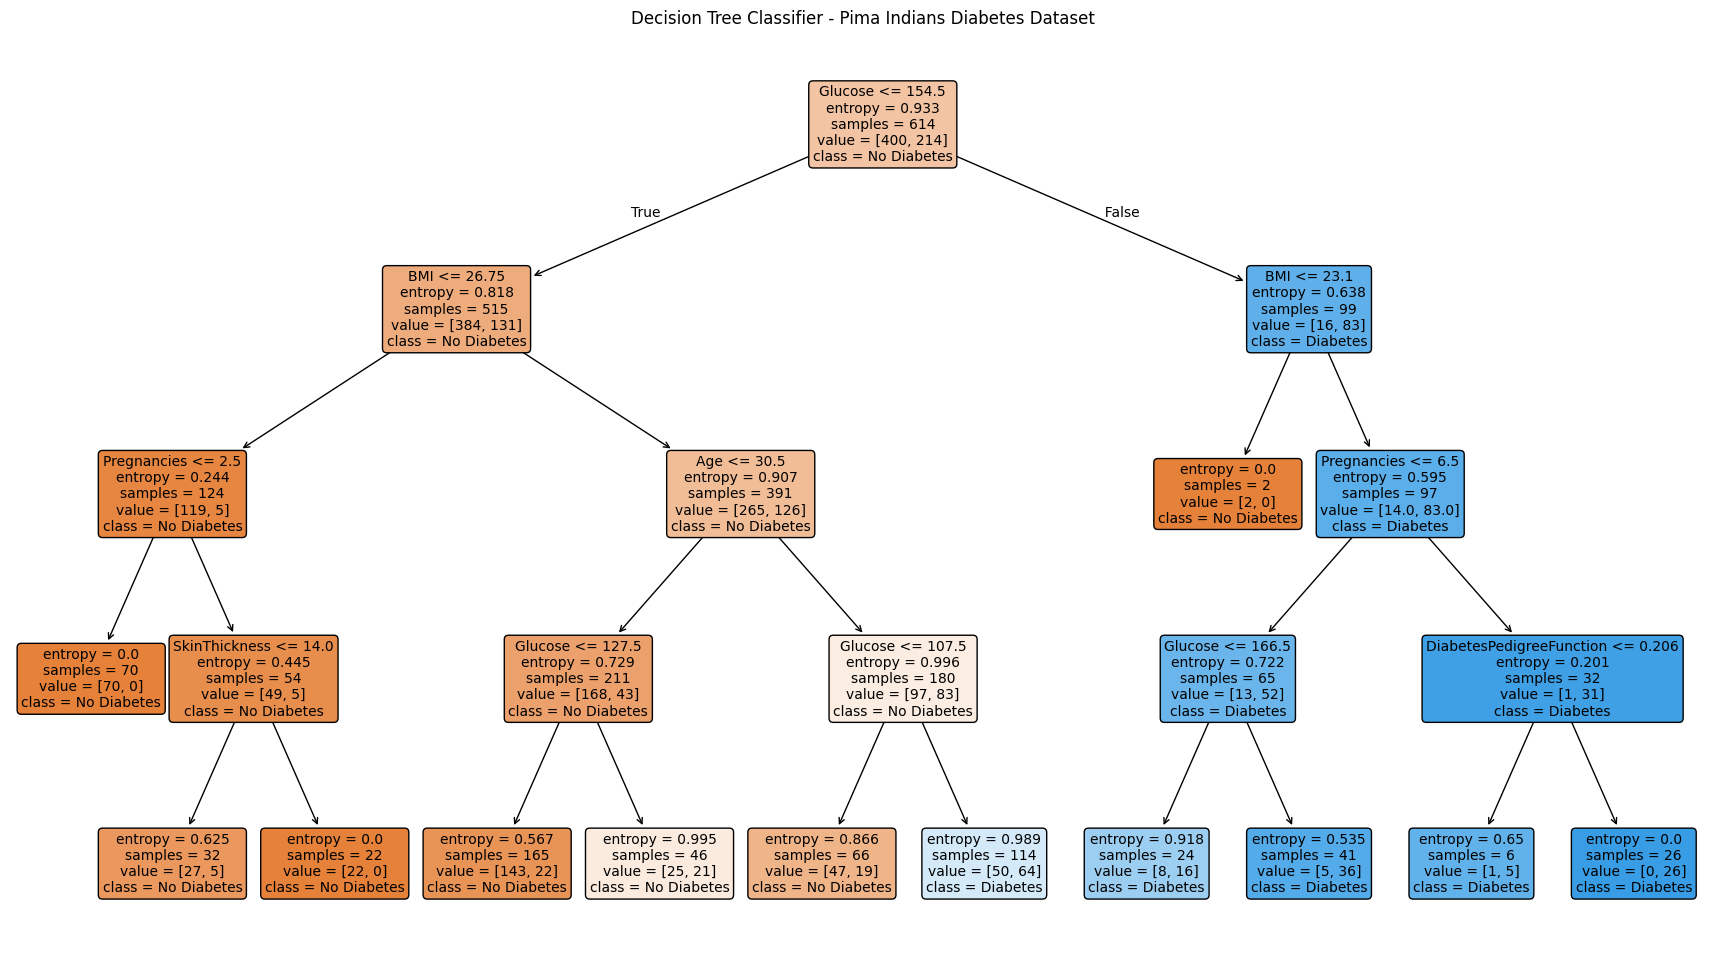

In [35]:
model.fit(X_train, y_train)

plt.figure(figsize=(22, 12))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Classifier - Pima Indians Diabetes Dataset")
plt.show()

Trains the decision tree and displays its structure graphically, showing features, conditions, and predicted classes at each node.

**Decision Tree with Greater Max Depth**

In this step, we create another decision tree with a greater maximum depth.

A greater depth allows the tree to create more branches and learn more complex patterns from the dataset.

In [31]:
# Decision Tree with greater depth

model_high = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=20,
    random_state=42
)

model_high.fit(X_train, y_train)

# Make predictions
y_pred_high = model_high.predict(X_test)

# Calculate accuracy
high_depth_accuracy = accuracy_score(y_test, y_pred_high)

print("Accuracy of High Depth Tree:", high_depth_accuracy)
print(classification_report(y_test, y_pred_high))

Accuracy of High Depth Tree: 0.7012987012987013
              precision    recall  f1-score   support

           0       0.75      0.80      0.78       100
           1       0.58      0.52      0.55        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



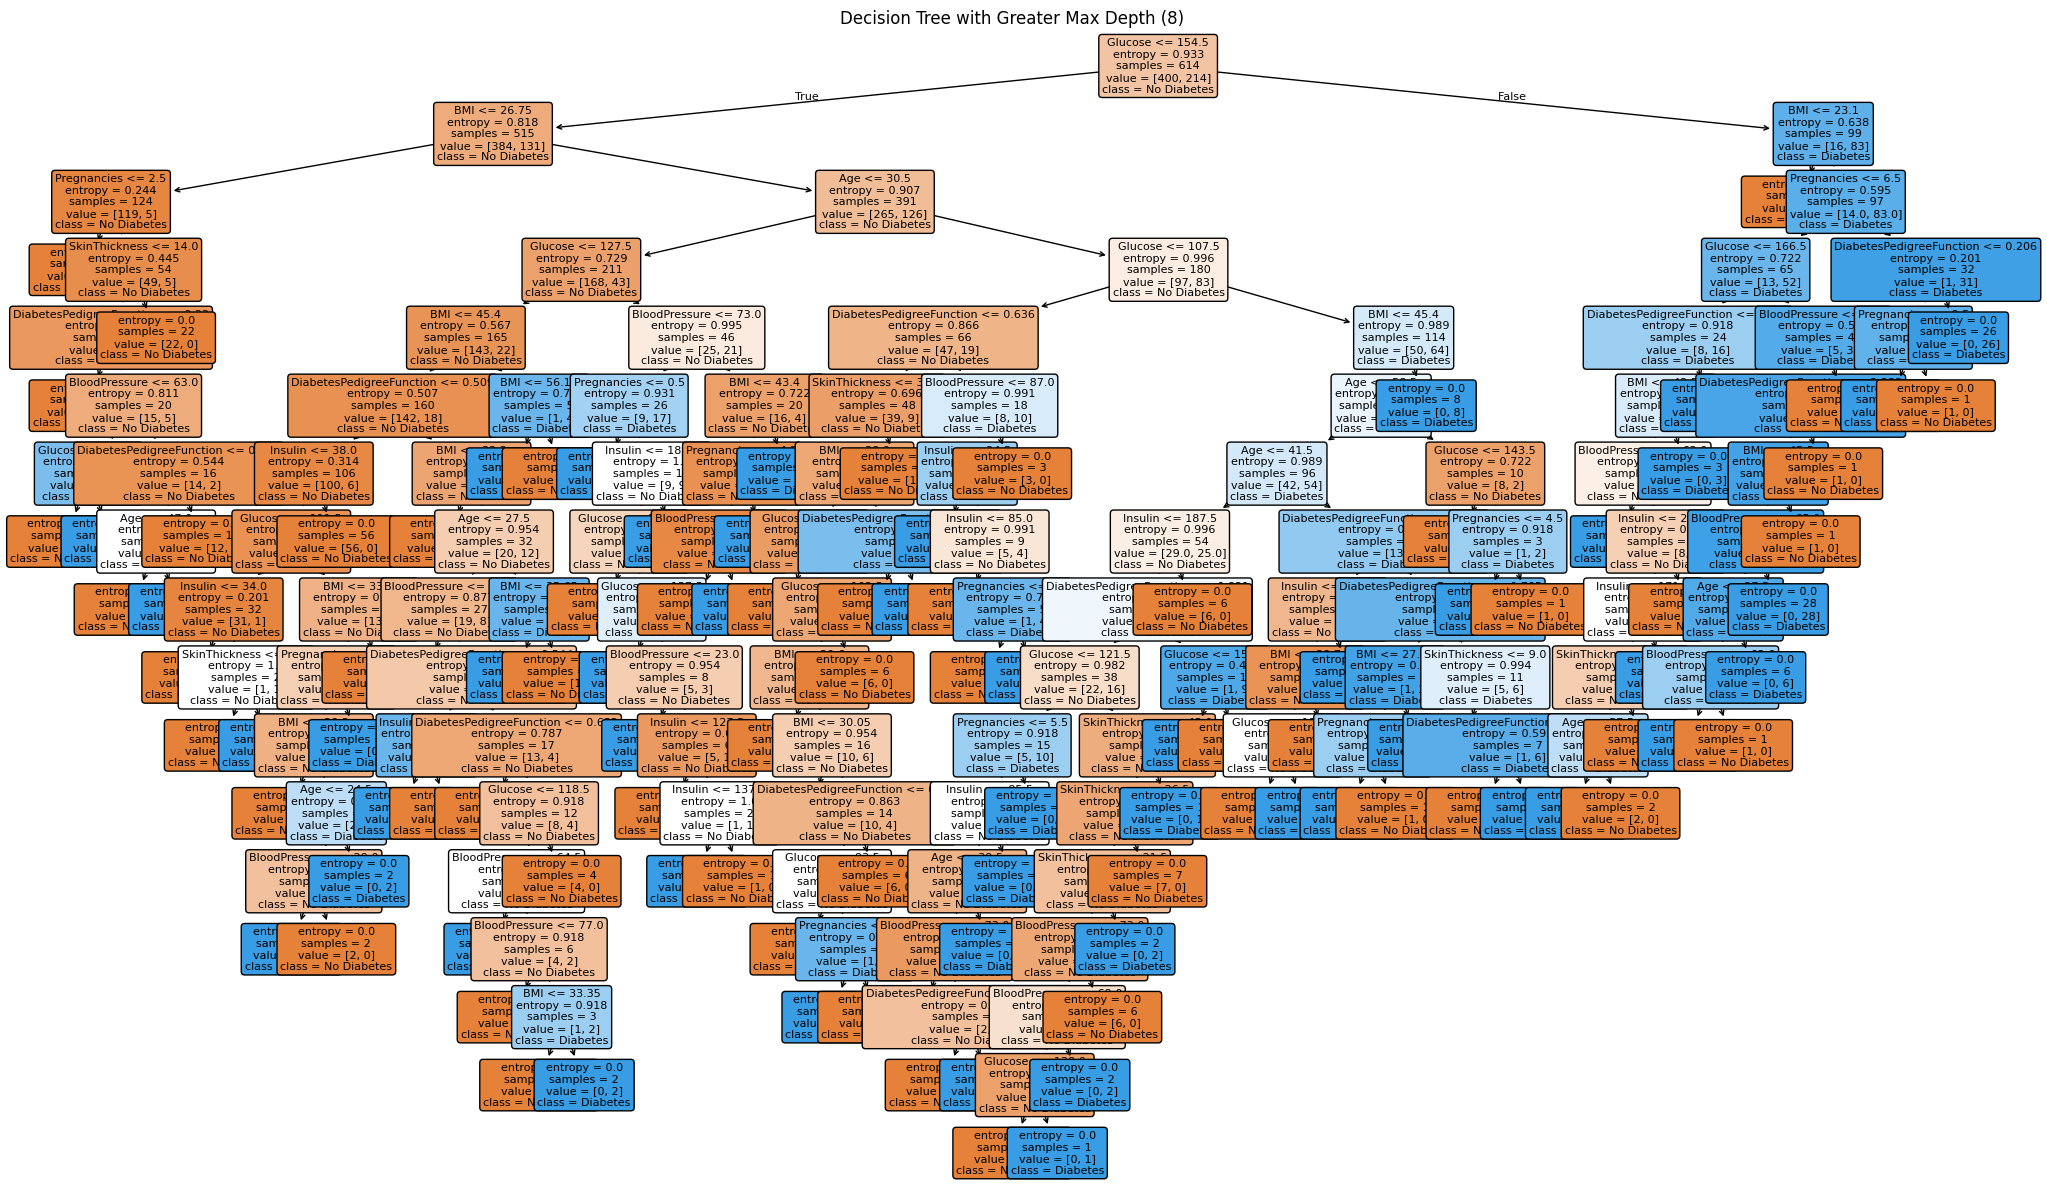

In [32]:
plt.figure(figsize=(25, 15))

plot_tree(
    model_high,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree with Greater Max Depth (8)")
plt.show()

**Comparison of Decision Trees**

We created two decision trees using different maximum depth values:

- First tree: max_depth = 4
- Second tree: max_depth = 20

The first tree is simpler and has fewer branches, while the second tree is more complex and can learn more detailed patterns.

We compare their accuracy to understand how changing the maximum depth affects model performance.

In [36]:
print("Low Depth Tree Accuracy:", low_depth_accuracy)
print("High Depth Tree Accuracy:", high_depth_accuracy)

Low Depth Tree Accuracy: 0.8051948051948052
High Depth Tree Accuracy: 0.7012987012987013


**Find Entropy, Information Gain and Gini for the Features**

In [37]:
from sklearn.tree import DecisionTreeClassifier

# Decision Tree using entropy
entropy_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=1,
    random_state=42
)

entropy_tree.fit(X_train, y_train)

print("Feature Information Gain:")

for feature, importance in zip(X.columns, entropy_tree.feature_importances_):
    print(feature, ":", importance)

Feature Information Gain:
Pregnancies : 0.0
Glucose : 1.0
BloodPressure : 0.0
SkinThickness : 0.0
Insulin : 0.0
BMI : 0.0
DiabetesPedigreeFunction : 0.0
Age : 0.0


Creates a one-level decision tree using Entropy to determine the feature that provides the highest information gain at the root.

**Calculate Gini-based Root**

In [38]:
gini_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=1,
    random_state=42
)

gini_tree.fit(X_train, y_train)

print("Feature importance using Gini:")

for feature, importance in zip(X.columns, gini_tree.feature_importances_):
    print(feature, ":", importance)

Feature importance using Gini:
Pregnancies : 0.0
Glucose : 1.0
BloodPressure : 0.0
SkinThickness : 0.0
Insulin : 0.0
BMI : 0.0
DiabetesPedigreeFunction : 0.0
Age : 0.0


Creates a one-level decision tree using the Gini impurity criterion.
Displays the importance of each feature according to the Gini criterion.

**Display the Root Node**

In [39]:
root_index = model.tree_.feature[0]

print("Root Node Feature:", X.columns[root_index])
print("Root Node Threshold:", model.tree_.threshold[0])

Root Node Feature: Glucose
Root Node Threshold: 154.5


Finds the feature used at the root (first) node of the decision tree.
Displays the root feature and the threshold value used by the tree for its first decision.

**Conclusion**:

In this practical, we used a Decision Tree Classifier to predict diabetes using the diabetes dataset.

We created two decision trees with different maximum depths (2 and 8) and compared their performance.

We observed how maximum depth affects the complexity of a decision tree. A smaller depth creates a simpler tree, whereas a greater depth creates a more complex tree.

We also explored Entropy, Information Gain, and Gini to understand how decision trees select features for splitting.